# Road Block Classification from Airborne LiDAR Point Clouds (SimplePointNet)

Original experiment notebook. Outputs are kept exactly as produced by the reported run.

To run it, place the dataset in `data/dataset/` (one sub-folder per class) or edit `MY_DATASET_ROOT` below. The same pipeline is available as plain scripts in `src/` (see the repository README).

## 1. Project Setup and Reproducibility

This section of the code handles the initial setup of the project environment, including importing necessary libraries and configuring settings to ensure reproducible results. Reproducibility is crucial in machine learning to ensure that experiments can be replicated and validated.



In [19]:

# Cell 1: Essential Library Imports

# Core utilities for interacting with the operating system (e.g., file paths)
import os
# Numerical operations, especially for loading .npy files
import numpy as np
# Main PyTorch library for neural networks and tensors
import torch
# Classes for creating custom datasets and efficiently loading data in batches
from torch.utils.data import Dataset, DataLoader, random_split
# Neural network modules (e.g., layers like Conv1d, Linear)
import torch.nn as nn
# Common neural network functions (e.g., activation functions like ReLU, pooling)
import torch.nn.functional as F
# Optimization algorithms (e.g., Adam)
import torch.optim as optim
# Plotting library for visualizations (e.g., loss curves, point clouds)
import matplotlib.pyplot as plt
# Utility for counting occurrences, used for class distribution
import collections
# Learning rate scheduler to adjust learning rate during training
from torch.optim.lr_scheduler import ReduceLROnPlateau
# For random selection in data sampling or visualization
import random # This import is crucial for random.seed()
# For generating all combinations of hyperparameters in Grid Search
from itertools import product
# Used to generate all combinations from the parameter grid
import itertools
# For better visualization of results
import pandas as pd
# For evaluating model performance metrics such as precision, recall, F1-score, Jaccard index, accuracy, and confusion matrix
from sklearn.metrics import precision_recall_fscore_support, jaccard_score, accuracy_score, confusion_matrix


def set_seed(seed):
    """
    Sets the random seed for reproducibility across different libraries.

    This function ensures that random operations yield the same results
    every time the code is executed, which is essential for debugging,
    comparing model performance, and verifying experimental outcomes.

    Args:
        seed (int): The integer value to use as the random seed.
    """
    random.seed(seed)       # Seed for Python's built-in random module
    np.random.seed(seed)    # Seed for NumPy's random number generator
    torch.manual_seed(seed) # Seed for PyTorch on CPU
    torch.cuda.manual_seed(seed) # Seed for PyTorch on a single GPU
    torch.cuda.manual_seed_all(seed) # Seed for PyTorch on all GPUs (if multiple are available)

    # Configure PyTorch to use deterministic algorithms where possible.
    # This might slightly reduce performance but ensures that the operations
    # are reproducible on CUDA-enabled GPUs.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False # Disables cuDNN auto-tuner for reproducibility
    print(f"Random seed set to {seed} for reproducibility.")

# --- Call the set_seed function at the beginning of your script ---
SEED = 42 # Defines a fixed seed value for reproducibility. This is a common practice.
set_seed(SEED) # Applies the chosen seed across all relevant libraries.

# Determines the device to be used for computations (GPU if available, otherwise CPU).
# Leveraging a GPU (CUDA) significantly speeds up neural network training.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Random seed set to 42 for reproducibility.
Using device: cuda


## 2. Dataset Configuration and Preprocessing Utility

This section defines global configuration parameters for the dataset and includes a utility function to scan the dataset and determine the largest point cloud. This information is critical for standardizing the input size for neural networks, which typically require fixed-size inputs.



In [20]:
# Cell 2: Global Configuration and Utility Function for Dataset Scanning

# Define the root directory where your dataset is stored.
# IMPORTANT: Update this path if your dataset is located elsewhere!
MY_DATASET_ROOT = 'data/dataset'

# Define the number of features per point in your dataset (e.g., X,Y,Z,RGB,Intensity).
MY_NUM_FEATURES = 11


def find_max_points_in_dataset(data_root_dir):
    """
    Scans the dataset directory to determine the maximum number of points
    present in any single .npy point cloud file.

    This function is crucial for understanding the variability in point cloud sizes
    and preparing for subsequent data preprocessing steps like padding or truncating
    to a uniform size, which is often required by neural networks.

    Args:
        data_root_dir (str): The root path to the dataset, where point cloud
                             files are stored in subdirectories.

    Returns:
        int: The maximum number of points found across all point cloud files.
             Returns 0 if the directory does not exist or no valid .npy files are found.
    """
    my_max_points = 0 # Initialize a variable to store the maximum number of points found
    my_files_found_count = 0 # Counter for the number of .npy files processed
    print(f"Scanning for the maximum number of points in: {data_root_dir}")

    # Check if the specified dataset directory exists.
    # If not, print an error and return 0, as no files can be scanned.
    if not os.path.exists(data_root_dir):
        print(f"Error: Dataset directory '{data_root_dir}' does not exist.")
        print("Please ensure the dataset is downloaded and the path is correct before running.")
        return 0

    # Walk through all directories and files starting from the data_root_dir.
    # This allows processing point clouds organized in subfolders.
    for root, dirs, files in os.walk(data_root_dir):
        # Exclude 'Features.txt' from the list of files to process, as it's not a point cloud.
        if 'Features.txt' in files:
            files.remove('Features.txt')

        # Iterate over each file found in the current directory.
        for file_name in files:
            # Check if the file is a NumPy array file, which is expected for point clouds.
            if file_name.endswith('.npy'):
                full_file_path = os.path.join(root, file_name) # Construct the full path to the file
                try:
                    # Load the point cloud data from the .npy file.
                    point_cloud = np.load(full_file_path)
                    # Get the number of points in the current point cloud (number of rows).
                    current_num_points = point_cloud.shape[0]
                    # Update the maximum number of points if the current point cloud is larger.
                    if current_num_points > my_max_points:
                        my_max_points = current_num_points
                    my_files_found_count += 1 # Increment the counter for successfully processed files
                except Exception as e:
                    # Catch and report any errors that occur during file loading,
                    # such as corrupted files or incorrect formats.
                    print(f"Error loading {full_file_path}: {e}")
                    print("This file might be corrupted or not in the expected .npy format. Skipping.")
                    continue # Continue to the next file even if an error occurs

    print(f"Finished scanning. Found {my_files_found_count} point cloud files in total.")
    return my_max_points # Return the overall maximum number of points found

## 3. Custom PyTorch Dataset for Point Clouds

This section defines a custom PyTorch `Dataset` class, `MyPointCloudDataset`, which is essential for handling the specific structure of the point cloud data. This class abstracts the data loading process, making it compatible with PyTorch's `DataLoader` for efficient batch processing during model training and evaluation.



In [21]:
# Cell 3: Custom PyTorch Dataset for Point Clouds

class MyPointCloudDataset(Dataset):
    """
    Custom PyTorch Dataset for loading point cloud data from .npy files.

    This dataset class is responsible for:
    1. Identifying all point cloud files and their associated class labels,
       which are inferred from the directory structure (each subdirectory
       represents a unique class).
    2. Establishing mappings between human-readable class names (strings)
       and their corresponding numerical integer IDs, and vice-versa.
    3. Loading individual point cloud files and their labels when requested
       by a PyTorch DataLoader.
    4. Selecting a predefined subset of features from the raw point cloud data.
    5. Applying Min-Max normalization to the selected features using
       pre-computed minimum and maximum values to scale data between 0 and 1.
    6. Integrating optional data augmentation transforms to increase
       the diversity of the training data.
    """
    def __init__(self, data_root_dir, max_points_to_pad_to, feature_min_vals=None, feature_max_vals=None, transform=None):
        """
        Initializes the dataset by scanning for point cloud files and class labels,
        and setting up feature selection, normalization, and augmentation.

        Args:
            data_root_dir (str): The absolute path to the root directory where the dataset
                                 is located. Each subdirectory within this path is expected
                                 to represent a distinct class.
            max_points_to_pad_to (int): The maximum number of points found in any point cloud
                                        in the entire dataset. While this parameter is received
                                        here, the actual padding/truncation to this size is
                                        typically handled later by a custom `collate_fn`
                                        function used with the `DataLoader`.
            feature_min_vals (np.ndarray, optional): A NumPy array containing the minimum
                                                    values for each of the `selected_feature_indices`.
                                                    These values are crucial for performing
                                                    Min-Max normalization. If None, normalization
                                                    is skipped.
            feature_max_vals (np.ndarray, optional): A NumPy array containing the maximum
                                                    values for each of the `selected_feature_indices`.
                                                    Used in conjunction with `feature_min_vals`
                                                    for Min-Max normalization. If None, normalization
                                                    is skipped.
            transform (callable, optional): An optional function or a composition of functions
                                            (e.g., from `torchvision.transforms`) that will be
                                            applied to the point cloud data after it has been
                                            loaded and potentially normalized. This is commonly
                                            used for data augmentation techniques like rotation
                                            or scaling of point clouds.
        """
        self.data_root_dir = data_root_dir
        self.max_points_to_pad_to = max_points_to_pad_to
        self.my_file_paths = []   # List to store the full file paths of all .npy point clouds
        self.my_labels = []       # List to store the corresponding integer labels for each point cloud

        # Defines the specific indices of features to be selected from the raw
        # point cloud data. This choice is based on prior feature tuning.
        # The selected features are: local x, local y, local z, red, green, blue,
        # intensity, planarity, linearity, sphericity, verticality.
        self.selected_feature_indices = [0, 1, 2, 3, 4, 5, 9, 11, 12, 13, 14]

        # Stores the minimum and maximum values for normalization.
        # These values should be pre-computed from the training dataset to prevent
        # data leakage from validation/test sets.
        self.feature_min_vals = feature_min_vals
        self.feature_max_vals = feature_max_vals

        # Stores the optional transformation (augmentation) function.
        self.transform = transform

        # Checks if normalization parameters are provided and if their lengths match
        # the number of selected features. Raises an error if there's a mismatch.
        if self.feature_min_vals is not None and self.feature_max_vals is not None:
            if not (len(self.feature_min_vals) == len(self.selected_feature_indices) and \
                    len(self.feature_max_vals) == len(self.selected_feature_indices)):
                raise ValueError(f"Length of feature_min_vals ({len(self.feature_min_vals)}) or feature_max_vals ({len(self.feature_max_vals)}) does not match the number of selected features ({len(self.selected_feature_indices)}).")
            print(f"Dataset initialized with normalization parameters for {len(self.selected_feature_indices)} features.")
        else:
            # Warns the user if normalization parameters are missing, indicating that
            # normalization will not be performed within the dataset itself.
            print("Warning: Normalization parameters (feature_min_vals, feature_max_vals) not provided. Features will NOT be normalized by the dataset itself.")

        # Ensures that the specified root directory for the dataset actually exists.
        # If not, it raises a FileNotFoundError to prevent further execution with an invalid path.
        if not os.path.exists(data_root_dir):
            raise FileNotFoundError(f"Dataset directory '{data_root_dir}' does not exist. Please check the path!")

        # Discovers class folders (subdirectories) within the data_root_dir.
        # Each subdirectory name is treated as a class label.
        my_class_folders = [d for d in os.listdir(data_root_dir)
                            if os.path.isdir(os.path.join(data_root_dir, d))]
        # Removes 'Features.txt' from the list if it's mistakenly identified as a directory,
        # and sorts the class folders for consistent ordering.
        my_class_folders = sorted([f for f in my_class_folders if f != 'Features.txt'])

        # Creates two dictionaries for easy mapping between class names (strings)
        # and their corresponding unique integer IDs, and vice-versa.
        self.label_to_id = {label_name: i for i, label_name in enumerate(my_class_folders)}
        self.id_to_label = {i: label_name for i, label_name in enumerate(my_class_folders)}
        print(f"Detected classes (from folder names): {my_class_folders}")
        print(f"Mapping from class name to ID: {self.label_to_id}")

        # Populates the `my_file_paths` and `my_labels` lists by iterating through
        # each class folder and collecting all `.npy` files and their assigned labels.
        for class_name in my_class_folders:
            current_class_path = os.path.join(data_root_dir, class_name)
            # Get files in the directory and sort them for deterministic order
            files_in_class_folder = sorted(os.listdir(current_class_path))
            for file_name in files_in_class_folder: # Iterate through the sorted files
                # Only add .npy files to the dataset lists
                if file_name.endswith('.npy'):
                    self.my_file_paths.append(os.path.join(current_class_path, file_name))
                    self.my_labels.append(self.label_to_id[class_name])

        print(f"Found a total of {len(self.my_file_paths)} point cloud files across all classes.")
        if not self.my_file_paths:
            print("Warning: No .npy files found in the specified class directories. Check data structure.")

    def __len__(self):
        """
        Returns the total number of samples (point clouds) in the dataset.

        This method is a required part of PyTorch's `Dataset` class, allowing
        `DataLoader` to know the size of the dataset.

        Returns:
            int: The total number of point cloud samples available in the dataset.
        """
        return len(self.my_file_paths)

    def __getitem__(self, idx):
        """
        Retrieves a single sample (point cloud data and its corresponding label)
        from the dataset given an index.

        This method is a required part of PyTorch's `Dataset` class, allowing
        `DataLoader` to fetch individual data points. It handles loading,
        feature selection, normalization, and optional data augmentation.

        Args:
            idx (int or torch.Tensor): The index of the sample to retrieve from the dataset.

        Returns:
            tuple: A tuple containing:
                - torch.Tensor: The processed point cloud data. Its shape will be
                                `(N_points_actual, N_selected_features)`. The number
                                of points (`N_points_actual`) can vary per sample
                                and is handled by `collate_fn` for batching.
                                The data type is `torch.float32`.
                - torch.Tensor: The integer class label for the point cloud.
                                The data type is `torch.long`.
                In case of a loading or processing error for a specific file,
                it returns an empty tensor for the point cloud and a label of -1,
                along with an error message.
        """
        # Converts the index to a Python integer if it's a PyTorch tensor,
        # ensuring compatibility with list indexing.
        if torch.is_tensor(idx):
            idx = idx.tolist()

        file_path = self.my_file_paths[idx] # Get the full path of the .npy file
        label_id = self.my_labels[idx]     # Get the integer label for the file

        try:
            # Loads the point cloud data from the .npy file using NumPy.
            # It's immediately cast to `float32` for PyTorch compatibility and memory efficiency.
            point_cloud = np.load(file_path).astype(np.float32)

            # Applies feature selection: keeps only the columns (features)
            # specified by `self.selected_feature_indices`.
            point_cloud = point_cloud[:, self.selected_feature_indices]

            # Applies Min-Max Normalization if `feature_min_vals` and `feature_max_vals`
            # were provided during dataset initialization.
            if self.feature_min_vals is not None and self.feature_max_vals is not None:
                # Calculates the range (max - min) for each selected feature.
                feature_range = self.feature_max_vals - self.feature_min_vals
                # Replaces any zero values in `feature_range` with a small epsilon
                # to prevent division by zero errors for features that have a constant value.
                feature_range[feature_range == 0] = 1e-6

                # Applies the Min-Max scaling formula: (value - min) / (max - min).
                point_cloud = (point_cloud - self.feature_min_vals) / feature_range

            # Applies the optional data augmentation transform (if provided).
            # This allows for dynamic modifications to the point cloud data during training.
            if self.transform:
                # The transform function is expected to operate on a NumPy array
                # and return a NumPy array.
                point_cloud = self.transform(point_cloud)

        except Exception as e:
            # If an error occurs during loading or processing (e.g., corrupted file),
            # an error message is printed, and an empty tensor with an invalid label (-1)
            # is returned. This allows the DataLoader to continue processing other samples.
            print(f"Error loading or processing file {file_path}: {e}")
            return torch.zeros((0, len(self.selected_feature_indices))), torch.tensor(-1, dtype=torch.long)

        # Converts the processed NumPy array point cloud to a PyTorch tensor
        # and ensures its data type is `float32`. The label is also converted to a
        # `torch.long` tensor, which is suitable for classification loss functions.
        return torch.from_numpy(point_cloud).to(torch.float32), torch.tensor(label_id, dtype=torch.long)

## 4. Custom Collate Function for DataLoader

This section introduces a custom `collate_fn` (collation function) named `my_collate_fn_pad`. This function is essential when working with datasets where individual samples (like point clouds) may have varying dimensions, specifically a different number of points. PyTorch's `DataLoader` requires batch elements to have consistent sizes. This `collate_fn` addresses this by padding or truncating point clouds to a uniform size, ensuring they can be grouped into tensors for efficient processing by a neural network.



In [22]:

# Cell 4: Custom Collate Function for DataLoader

def my_collate_fn_pad(batch_data_list, max_points_to_pad_to, num_features):
    """
    A custom collation function designed for PyTorch DataLoaders.
    This function processes a list of individual samples (each consisting of
    a point cloud and its corresponding label) and aggregates them into a
    single batch. A key functionality is to standardize the number of points
    in each point cloud by either padding with zeros or truncating, ensuring
    all point clouds in a batch have a uniform dimension.

    Args:
        batch_data_list (list): A list of tuples, where each tuple contains
                                a `(point_cloud, label)` pair. Each `point_cloud`
                                is a PyTorch Tensor that may have a varying number
                                of points (rows).
        max_points_to_pad_to (int): The target number of points (rows) for each
                                    point cloud in the output batch. Point clouds
                                    with fewer points will be padded, and those
                                    with more points will be truncated to this size.
        num_features (int): The number of features (columns) per point in the
                            point cloud. This value is used to correctly size
                            the padding tensor. This should correspond to the
                            number of `selected_feature_indices` from the dataset.

    Returns:
        tuple: A tuple containing two PyTorch Tensors:
            - torch.Tensor: A batch of uniformly sized point clouds. Its shape
                            will be `(batch_size, max_points_to_pad_to, num_features)`.
                            Points are padded with zeros or truncated.
            - torch.Tensor: A batch of corresponding class labels. Its shape will be
                            `(batch_size,)`.
            If no valid samples are present in the `batch_data_list` after filtering
            (e.g., all samples failed to load), empty tensors with the correct
            number of dimensions are returned to prevent errors.
    """
    # Filters out any samples that might have failed to load within the `Dataset`'s
    # `__getitem__` method (which would return point clouds with 0 rows).
    # This ensures that only valid point clouds are included in the batch.
    my_filtered_batch = [item for item in batch_data_list if item[0].shape[0] > 0]

    # If, after filtering, no valid samples remain in the batch (e.g., all files
    # failed to load for a given batch), return empty tensors with appropriate
    # dimensions to prevent errors in the DataLoader.
    if not my_filtered_batch:
        # Returns an empty point cloud tensor with the expected shape
        # (0 batch size, target points, number of features)
        # and an empty label tensor (0 batch size).
        return torch.empty(0, max_points_to_pad_to, num_features), torch.empty(0)

    # Unzips the filtered list of (point_cloud, label) tuples into two separate lists:
    # one for point clouds and one for labels.
    point_clouds_raw, labels_raw = zip(*my_filtered_batch)

    my_padded_point_clouds = [] # List to store point clouds after padding/truncation
    for pc in point_clouds_raw:
        current_num_points = pc.shape[0] # Get the current number of points in the point cloud

        if current_num_points > max_points_to_pad_to:
            # If the current point cloud has more points than the target, truncate it
            # by taking only the first `max_points_to_pad_to` points.
            padded_pc = pc[:max_points_to_pad_to, :]
        elif current_num_points < max_points_to_pad_to:
            # If the current point cloud has fewer points than the target, pad it with zeros.
            padding_needed = max_points_to_pad_to - current_num_points
            # Creates a tensor of zeros with the required number of padding rows
            # and the same number of features as the point cloud.
            padding_tensor = torch.zeros(padding_needed, num_features, dtype=pc.dtype)
            # Concatenates the original point cloud with the padding tensor along dimension 0 (rows).
            padded_pc = torch.cat([pc, padding_tensor], dim=0)
        else:
            # If the point cloud already has the exact target number of points, use it as is.
            padded_pc = pc
        my_padded_point_clouds.append(padded_pc) # Add the processed point cloud to the list

    # Stacks all individual padded/truncated point clouds into a single batch tensor.
    # This results in a tensor of shape (batch_size, max_points_to_pad_to, num_features).
    point_clouds_batch_tensor = torch.stack(my_padded_point_clouds)
    # Converts the list of integer labels into a single PyTorch tensor of type `long`.
    labels_batch_tensor = torch.tensor(labels_raw, dtype=torch.long)

    return point_clouds_batch_tensor, labels_batch_tensor

## 5. Automated Calculation of Normalization Statistics

This section calculates the minimum and maximum values for each selected feature across the training dataset. These statistics are essential for Min-Max normalization, which scales feature values to a consistent range (e.g., 0 to 1). This step helps stabilize neural network training. It's crucial that these statistics are derived *only* from the training data to prevent data leakage.



In [23]:
# Cell 5: Automated Calculation of Normalization Statistics

# Defines the dataset root for calculating normalization statistics.
# This should point to the training data. If your dataset has a separate 'train' subfolder,
TRAIN_DATA_ROOT_FOR_STATS = MY_DATASET_ROOT

# Determines the maximum number of points in any point cloud to ensure `MyPointCloudDataset`
# can be properly instantiated.
MY_GLOBAL_MAX_POINTS_FOR_STATS = find_max_points_in_dataset(TRAIN_DATA_ROOT_FOR_STATS)

# Handles cases where no point clouds are found, setting a default max points and issuing a warning.
if MY_GLOBAL_MAX_POINTS_FOR_STATS == 0:
    print("Warning: MY_GLOBAL_MAX_POINTS_FOR_STATS is 0. Check data path or data existence.")
    MY_GLOBAL_MAX_POINTS_FOR_STATS = 4096

print(f"Starting calculation of min/max values from training data in: {TRAIN_DATA_ROOT_FOR_STATS}")

try:
    # Instantiates `MyPointCloudDataset` to collect statistics.
    # Normalization and augmentation are disabled (`None`) during this step.
    stats_dataset = MyPointCloudDataset(
        data_root_dir=TRAIN_DATA_ROOT_FOR_STATS,
        max_points_to_pad_to=MY_GLOBAL_MAX_POINTS_FOR_STATS,
        feature_min_vals=None,
        feature_max_vals=None,
        transform=None
    )

    # Verifies that the dataset is not empty before proceeding.
    if len(stats_dataset) == 0:
        raise ValueError(f"No point cloud files found in {TRAIN_DATA_ROOT_FOR_STATS}. Cannot calculate statistics.")

    # Initializes min/max arrays based on the number of selected features.
    num_selected_features_for_stats = len(stats_dataset.selected_feature_indices)
    global_min_vals = np.array([float('inf')] * num_selected_features_for_stats, dtype=np.float32)
    global_max_vals = np.array([float('-inf')] * num_selected_features_for_stats, dtype=np.float32)

    # Iterates through the dataset to find the overall min/max for each feature.
    for i in range(len(stats_dataset)):
        point_cloud, _ = stats_dataset[i] # Retrieves a point cloud (already feature-selected).

        if isinstance(point_cloud, torch.Tensor):
            point_cloud = point_cloud.numpy()

        if point_cloud.shape[0] == 0: # Skips empty point clouds.
            continue

        # Updates the global min/max with values from the current point cloud.
        global_min_vals = np.minimum(global_min_vals, point_cloud.min(axis=0))
        global_max_vals = np.maximum(global_max_vals, point_cloud.max(axis=0))

    # Prints the calculated statistics.
    print("\nCalculated Global Min Values for Selected Features:")
    print(global_min_vals)
    print("\nCalculated Global Max Values for Selected Features:")
    print(global_max_vals)

    # Stores the calculated min/max values for later use in dataset instantiation.
    calculated_train_min_vals = global_min_vals
    calculated_train_max_vals = global_max_vals

    print("\nMin/Max calculation complete. 'calculated_train_min_vals' and 'calculated_train_max_vals' are now available.")

except Exception as e:
    # Handles and reports errors during the calculation process.
    print(f"\nAN ERROR OCCURRED during min/max calculation: {e}")
    print("Please check TRAIN_DATA_ROOT_FOR_STATS and ensure your dataset structure is correct.")
    calculated_train_min_vals = None
    calculated_train_max_vals = None

Scanning for the maximum number of points in: data/dataset
Finished scanning. Found 1425 point cloud files in total.
Starting calculation of min/max values from training data in: data/dataset
Detected classes (from folder names): ['2lanes', '3lanes', 'crossing', 'split4lanes', 'split6lanes', 'transition']
Mapping from class name to ID: {'2lanes': 0, '3lanes': 1, 'crossing': 2, 'split4lanes': 3, 'split6lanes': 4, 'transition': 5}
Found a total of 1425 point cloud files across all classes.

Calculated Global Min Values for Selected Features:
[    0.     0.     0.     0.     0.     0. 19092.     0.     0.     0.
     0.]

Calculated Global Max Values for Selected Features:
[2.9999693e+01 2.4903748e+01 2.0389999e+01 2.5600000e+02 2.5600000e+02
 2.5600000e+02 6.5535000e+04 9.9989998e-01 1.0000000e+00 7.5230503e-01
 9.9996734e-01]

Min/Max calculation complete. 'calculated_train_min_vals' and 'calculated_train_max_vals' are now available.


## 6. SimplePointNet Model Definition

This section defines `SimplePointNet`, a neural network architecture inspired by the PointNet model, designed for classifying 3D point cloud data. PointNet is known for its ability to directly process unordered point sets.



In [24]:

# Cell 6: SimplePointNet Model Definition

class SimplePointNet(nn.Module):
    """
    A simplified PointNet model for point cloud classification.

    This model processes raw point cloud data to classify it into predefined categories.
    It comprises three main stages:
    1. Per-point feature extraction: Shared Multi-Layer Perceptrons (MLPs)
       process each point independently using 1D convolutions.
    2. Global feature aggregation: A symmetric function (max pooling)
       combines per-point features into a single global feature vector.
    3. Classification head: Standard MLPs map the global feature to class scores.
    """
    def __init__(self, num_features, num_classes, dropout_rate=0.4):
        """
        Initializes the SimplePointNet model's layers.

        Args:
            num_features (int): The number of input features for each point.
            num_classes (int): The number of distinct classes for classification.
            dropout_rate (float): The probability of an element being zeroed
                                  during dropout for regularization, preventing overfitting.
        """
        super(SimplePointNet, self).__init__()

        # --- Part 1: Per-Point Feature Learning (Shared MLPs) ---
        # These layers apply a transformation to each point independently.
        # Conv1d with kernel_size=1 behaves like an MLP applied to each point's features.
        self.mlp1_conv = nn.Conv1d(num_features, 64, kernel_size=1)
        self.mlp1_bn = nn.BatchNorm1d(64) # Batch Normalization for stable training

        self.mlp2_conv = nn.Conv1d(64, 128, kernel_size=1)
        self.mlp2_bn = nn.BatchNorm1d(128)

        self.mlp3_conv = nn.Conv1d(128, 1024, kernel_size=1)
        self.mlp3_bn = nn.BatchNorm1d(1024) # Outputs high-dimensional features for each point

        # --- Part 2: Classification Head ---
        # These layers process the aggregated global feature vector to produce class scores.
        self.fc1 = nn.Linear(1024, 512)
        self.fc1_bn = nn.BatchNorm1d(512)
        self.dropout1 = nn.Dropout(p=dropout_rate) # Dropout layer for regularization

        self.fc2 = nn.Linear(512, 256)
        self.fc2_bn = nn.BatchNorm1d(256)
        self.dropout2 = nn.Dropout(p=dropout_rate)

        self.fc3 = nn.Linear(256, num_classes) # Final layer outputs raw class scores (logits)

    def forward(self, x):
        """
        Defines the forward pass logic of the SimplePointNet model.

        Args:
            x (torch.Tensor): Input batch of point clouds.
                              Expected shape: `(batch_size, num_points, num_features)`.

        Returns:
            torch.Tensor: Output tensor containing raw predicted class scores (logits)
                          for each point cloud in the batch.
                          Shape: `(batch_size, num_classes)`.
        """
        # Step 1: Reshape input for Conv1d.
        # Conv1d expects input as (batch_size, channels/features, sequence_length/points).
        # We permute from (B, N, F) to (B, F, N).
        x = x.permute(0, 2, 1)

        # Step 2: Apply per-point feature learning layers.
        # Each point's features are processed through shared MLP blocks.
        x = F.relu(self.mlp1_bn(self.mlp1_conv(x))) # Output: (B, 64, N)
        x = F.relu(self.mlp2_bn(self.mlp2_conv(x))) # Output: (B, 128, N)
        x = F.relu(self.mlp3_bn(self.mlp3_conv(x))) # Output: (B, 1024, N)

        # Step 3: Global feature aggregation using max pooling.
        # Max pooling along the point dimension (dim=2) extracts a single,
        # permutation-invariant global feature vector for each point cloud.
        x = torch.max(x, 2)[0] # Output: (B, 1024). [0] gets the max values.

        # Step 4: Pass the global feature vector through the classification head.
        x = F.relu(self.fc1_bn(self.fc1(x)))
        x = self.dropout1(x) # Apply dropout for regularization

        x = F.relu(self.fc2_bn(self.fc2(x)))
        x = self.dropout2(x) # Apply dropout

        x = self.fc3(x) # Final layer outputs logits; CrossEntropyLoss expects these directly.

        return x

## 7. Main Execution Block - Data Initialization and Model Setup

This block serves as the primary entry point for setting up the data pipeline and initializing the classification model. It performs essential steps such as determining point cloud dimensions, creating the custom dataset, configuring the data loader, and preparing the `SimplePointNet` model for training.



--- Starting Main Project Execution ---
Scanning for the maximum number of points in: data/dataset
Finished scanning. Found 1425 point cloud files in total.

--- Initializing MyPointCloudDataset with normalization parameters ---
Dataset initialized with normalization parameters for 11 features.
Detected classes (from folder names): ['2lanes', '3lanes', 'crossing', 'split4lanes', 'split6lanes', 'transition']
Mapping from class name to ID: {'2lanes': 0, '3lanes': 1, 'crossing': 2, 'split4lanes': 3, 'split6lanes': 4, 'transition': 5}
Found a total of 1425 point cloud files across all classes.

Detected 6 unique classes in the dataset.

--- Testing the DataLoader with a Sample Batch ---
Batch 1:
  Point Clouds Batch Shape: torch.Size([4, 16661, 11])
  Labels Batch: tensor([3, 3, 3, 3])
Batch 2:
  Point Clouds Batch Shape: torch.Size([4, 16661, 11])
  Labels Batch: tensor([1, 1, 4, 3])

Data loading setup complete and verified!

--- Initializing the Simple PointNet Model for initial test --

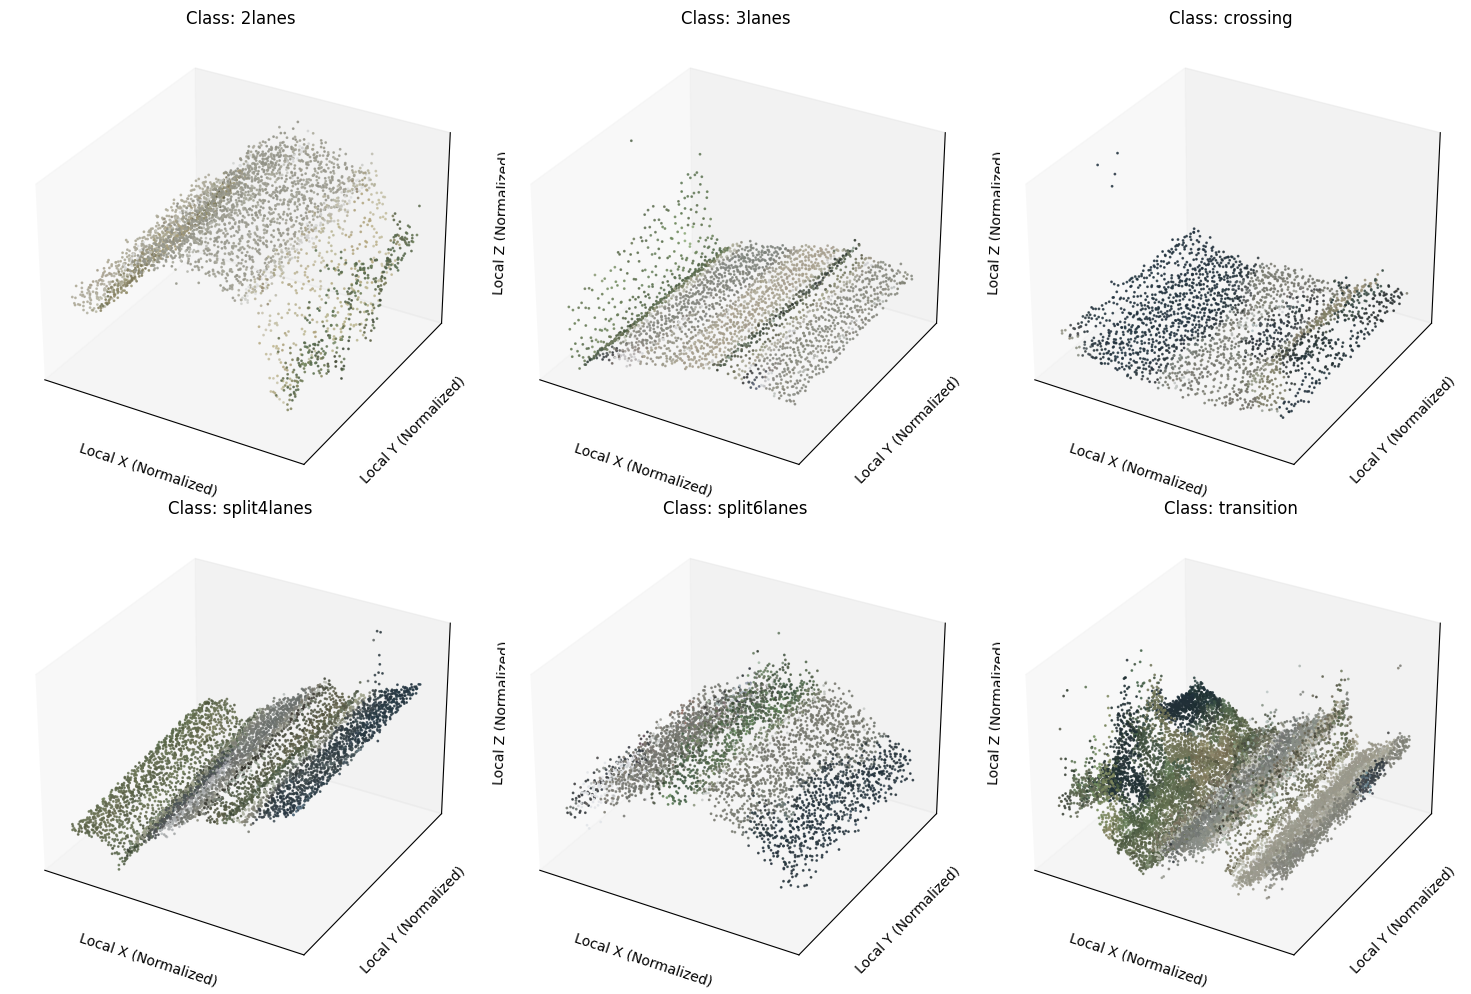


Visualization complete. A window with sample point cloud plots should have appeared.


In [25]:
# Cell 7: Main Execution Block - Data Initialization and Model Setup

if __name__ == "__main__":
    print("--- Starting Main Project Execution ---")

    # Step 1: Automatically find the maximum number of points across all data.
    # This is critical for padding/truncating point clouds to a uniform size for batching.
    MY_GLOBAL_MAX_POINTS = find_max_points_in_dataset(MY_DATASET_ROOT)

    # Ensures that point cloud data was found; exits if the dataset path is incorrect or empty.
    if MY_GLOBAL_MAX_POINTS == 0:
        print("\nInitialization failed: No point cloud data found or incorrect dataset path.")
        print("Please verify 'MY_DATASET_ROOT' and ensure it contains .npy files in class subfolders.")
        exit()
    else:
        # IMPORTANT: `calculated_train_min_vals` and `calculated_train_max_vals`
        # from Cell 5 (Automated Normalization Statistics Calculation) must be available.

        # Step 2: Initialize the custom dataset (`MyPointCloudDataset`).
        # This uses the determined maximum points for padding and the pre-calculated
        # normalization statistics (`min_vals`, `max_vals`) for feature scaling.
        # Data augmentation is explicitly set to `None` at this stage as it will be
        # applied selectively to the training subset later.
        print("\n--- Initializing MyPointCloudDataset with normalization parameters ---")
        my_dataset = MyPointCloudDataset(
            data_root_dir=MY_DATASET_ROOT,
            max_points_to_pad_to=MY_GLOBAL_MAX_POINTS,
            feature_min_vals=calculated_train_min_vals,
            feature_max_vals=calculated_train_max_vals,
            transform=None
        )

        # Determines the total number of unique classes detected from the dataset structure.
        my_num_classes = len(my_dataset.label_to_id)
        print(f"\nDetected {my_num_classes} unique classes in the dataset.")

        # Step 3: Create a PyTorch `DataLoader` for initial data pipeline testing.
        # This DataLoader facilitates efficient batching of data.
        # A custom `collate_fn` (`my_collate_fn_pad`) is used to handle variable point cloud sizes,
        # ensuring all samples in a batch are padded/truncated to `MY_GLOBAL_MAX_POINTS`.
        # The number of selected features is passed to the collate function.
        my_data_loader = DataLoader(
            my_dataset,
            batch_size=4,
            shuffle=True,
            collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices))
        )

        # Step 4: Test the DataLoader with a sample batch to confirm correct data loading and shaping.
        print("\n--- Testing the DataLoader with a Sample Batch ---")
        for i, (point_clouds_batch, labels_batch) in enumerate(my_data_loader):
            print(f"Batch {i+1}:")
            print(f"  Point Clouds Batch Shape: {point_clouds_batch.shape}") # Expected: (batch_size, MAX_POINTS, NUM_FEATURES)
            print(f"  Labels Batch: {labels_batch}")
            if i == 1: # Checks the first two batches.
                break
        print("\nData loading setup complete and verified!")

        # Step 5: Initialize the `SimplePointNet` model.
        # The model is configured with the number of selected input features and the total classes.
        # A placeholder `dropout_rate` is used, which will be optimized later via Grid Search.
        print("\n--- Initializing the Simple PointNet Model for initial test ---")
        model = SimplePointNet(num_features=len(my_dataset.selected_feature_indices), num_classes=my_num_classes, dropout_rate=0.4)
        print(model) # Prints the model architecture summary.

        # Moves the model to the available computational device (GPU if CUDA is available, otherwise CPU).
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print(f"Using device: {device}")
        model.to(device)

        # Optional: Performs a quick forward pass test with a sample batch to ensure the model runs without errors.
        try:
            sample_point_clouds, _ = next(iter(my_data_loader))
            print(f"\nTesting model with a sample batch of shape: {sample_point_clouds.shape}")
            sample_point_clouds = sample_point_clouds.to(device)
            output = model(sample_point_clouds)
            print(f"Model output (logits) shape: {output.shape}")
            print("Model initialized and tested successfully with a forward pass!")
        except Exception as e:
            print(f"Error during initial model forward pass test: {e}")
            print("Verify data loader output and model input expectations.")

        # --- Visualization of one random point cloud from each class for inspection. ---
        # Collects and plots a single random point cloud from each detected class.
        # This helps in visually inspecting the data and confirming correct loading and feature processing.
        print("\n--- Visualizing One Random Point Cloud from Each Class ---")
        samples_to_visualize = {}
        class_indices = {label_id: [] for label_id in my_dataset.id_to_label.keys()}
        for i, label_id in enumerate(my_dataset.my_labels):
            class_indices[label_id].append(i)

        for label_id, indices in class_indices.items():
            if indices:
                random_idx = random.choice(indices)
                pc_data, pc_label_id = my_dataset.__getitem__(random_idx)

                if pc_data.shape[0] > 0:
                    class_name = my_dataset.id_to_label[pc_label_id.item()]
                    samples_to_visualize[class_name] = pc_data.numpy()
                    print(f"Collected sample for class: '{class_name}' ({pc_data.shape[0]} points)")
                else:
                    print(f"Warning: Skipped empty point cloud for class ID {label_id} at index {random_idx}.")

        plt.figure(figsize=(15, 10))
        num_classes_to_plot = len(samples_to_visualize)
        cols = 3
        rows = (num_classes_to_plot + cols - 1) // cols

        plot_idx = 1
        for class_name, pc_data in samples_to_visualize.items():
            ax = plt.subplot(rows, cols, plot_idx, projection='3d')

            xs = pc_data[:, 0]
            ys = pc_data[:, 1]
            zs = pc_data[:, 2]

            colors = None
            # If RGB features (indices 3,4,5 in the original data) are selected and present, use them for coloring.
            if pc_data.shape[1] >= 6:
                colors = pc_data[:, 3:6]
                if colors.max() > 1.05: # Checks if color values are still in 0-255 range and normalizes if needed.
                    colors = colors / 255.0
                colors = np.clip(colors, 0, 1) # Clips values to ensure valid RGB range [0, 1].

            ax.scatter(xs, ys, zs, s=1, c=colors, alpha=0.8)

            ax.set_xlabel('Local X (Normalized)')
            ax.set_ylabel('Local Y (Normalized)')
            ax.set_zlabel('Local Z (Normalized)')
            ax.set_title(f'Class: {class_name}')

            # Hides axis ticks for cleaner visualization.
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_zticks([])

            plot_idx += 1

        plt.tight_layout() # Adjusts subplot parameters for a tight layout.
        plt.show() # Displays the plots.
        print("\nVisualization complete. A window with sample point cloud plots should have appeared.")

## 8. Dataset Splitting, DataLoader Creation, and Class Weight Calculation

This section handles crucial data preparation steps: defining data augmentation techniques, splitting the dataset into training, validation, and test sets, creating PyTorch DataLoaders for efficient batch processing, and calculating class weights to address potential class imbalance during training.



In [26]:
# Cell 8: Dataset Splitting, DataLoader Creation, and Class Weight Calculation

# --- Data Augmentation Functions ---
# These functions apply transformations to point clouds (NumPy arrays) to
# increase dataset diversity and improve model generalization.

def rotate_point_cloud(point_cloud):
    """Randomly rotates the point cloud around the Z-axis."""
    if point_cloud.shape[0] == 0: return point_cloud
    rotation_angle = np.random.uniform() * 2 * np.pi
    cosval, sinval = np.cos(rotation_angle), np.sin(rotation_angle)
    rotation_matrix = np.array([[cosval, -sinval, 0], [sinval, cosval, 0], [0, 0, 1]], dtype=np.float32)
    point_cloud[:, :3] = np.dot(point_cloud[:, :3].reshape(-1, 3), rotation_matrix)
    return point_cloud

def jitter_point_cloud(point_cloud, sigma=0.01, clip=0.05):
    """Adds random Gaussian noise (jitter) to point positions."""
    if point_cloud.shape[0] == 0: return point_cloud
    jitter = np.clip(sigma * np.random.randn(point_cloud.shape[0], 3), -clip, clip)
    point_cloud[:, :3] += jitter
    return point_cloud

def scale_point_cloud(point_cloud, min_scale=0.8, max_scale=1.2):
    """Randomly scales point cloud coordinates uniformly."""
    if point_cloud.shape[0] == 0: return point_cloud
    scale_factor = np.random.uniform(min_scale, max_scale)
    point_cloud[:, :3] *= scale_factor
    return point_cloud

def shift_point_cloud(point_cloud, shift_range=0.1):
    """Randomly shifts point cloud coordinates along each axis."""
    if point_cloud.shape[0] == 0: return point_cloud
    shift = np.random.uniform(-shift_range, shift_range, size=(1, 3))
    point_cloud[:, :3] += shift
    return point_cloud

def random_point_dropout(point_cloud, max_dropout_ratio=0.1):
    """Randomly removes a percentage of points from the point cloud."""
    if point_cloud.shape[0] == 0: return point_cloud
    dropout_ratio = np.random.uniform(0, max_dropout_ratio)
    num_points = point_cloud.shape[0]
    num_dropout = int(num_points * dropout_ratio)
    if num_dropout > 0:
        dropout_indices = np.random.choice(num_points, num_dropout, replace=False)
        point_cloud = np.delete(point_cloud, dropout_indices, axis=0)
    return point_cloud

# `PointCloudCompose` allows chaining multiple augmentation functions.
class PointCloudCompose:
    def __init__(self, transforms):
        self.transforms = transforms
    def __call__(self, img):
        for t in self.transforms:
            img = t(img)
        return img

# Defines the augmentation pipeline for the training set.
# Validation and test sets do not undergo augmentation.
train_transforms =  None
"""PointCloudCompose([
    rotate_point_cloud,
    lambda pc: jitter_point_cloud(pc, sigma=0.0005, clip=0.001),
    lambda pc: scale_point_cloud(pc, min_scale=0.99, max_scale=1.01),
    lambda pc: shift_point_cloud(pc, shift_range=0.005),
    lambda pc: random_point_dropout(pc, max_dropout_ratio=0.01)
]) """

val_test_transforms = None

BATCH_SIZE = 8 # Default batch size, adjustable for grid search.

# Step 6: Split Dataset into Training, Validation, and Test Sets.
print("\n--- Splitting Dataset into Training, Validation, and Test Sets ---")

# Defines split ratios.
train_ratio, val_ratio, test_ratio = 0.80, 0.15, 0.05
total_size = len(my_dataset)
train_size = int(train_ratio * total_size)
val_size = int(val_ratio * total_size)
test_size = total_size - train_size - val_size # Accounts for rounding.

# `random_split` creates subsets (views) of the base dataset.
train_dataset_base, val_dataset_base, test_dataset_base = random_split(
    my_dataset, [train_size, val_size, test_size]
)

print(f"Total dataset size: {total_size} samples")
print(f"Training set size (base): {len(train_dataset_base)} samples")
print(f"Validation set size (base): {len(val_dataset_base)} samples")
print(f"Test set size (base): {len(test_dataset_base)} samples")

# --- Create Augmented Training Dataset using a Wrapper ---
# A `SubsetWithTransform` wrapper is used because `random_split` returns `Subset` objects
# which cannot directly have transforms assigned. This wrapper applies the specified
# transforms to the point cloud data *only* when accessed.
class SubsetWithTransform(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, idx):
        point_cloud, label = self.subset[idx]
        if self.transform:
            # Converts PyTorch Tensor to NumPy for augmentation, then back to Tensor.
            point_cloud_np = point_cloud.numpy() if isinstance(point_cloud, torch.Tensor) else point_cloud
            point_cloud_np = self.transform(point_cloud_np)
            point_cloud = torch.from_numpy(point_cloud_np).to(torch.float32)
        return point_cloud, label

    def __len__(self):
        return len(self.subset)

# Applies augmentation only to the training split.
train_dataset = SubsetWithTransform(train_dataset_base, transform=train_transforms)
val_dataset = SubsetWithTransform(val_dataset_base, transform=val_test_transforms)
test_dataset = SubsetWithTransform(test_dataset_base, transform=val_test_transforms)

print(f"Augmented training set size: {len(train_dataset)} samples")
print(f"Validation set size (no augmentation): {len(val_dataset)} samples")
print(f"Test set size (no augmentation): {len(test_dataset)} samples")

# Create DataLoaders for each dataset split.
# `collate_fn` handles padding/truncation to `MY_GLOBAL_MAX_POINTS`.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True, # Shuffle training data for randomness.
    collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices)),
    num_workers=0 # Set higher for faster loading on multi-core systems.
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # No need to shuffle validation data.
    collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices)),
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # No need to shuffle test data.
    collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices)),
    num_workers=0
)

print("\nDataLoaders for training (augmented), validation, and testing created.")

# --- Automated Class Distribution Check & Class Weights Calculation ---
# This block analyzes the training set's class distribution and calculates
# inverse frequency weights to help the model learn from imbalanced classes.
print("\n--- Checking Training Data Class Distribution & Calculating Class Weights ---")

dynamic_class_counts_counter = collections.Counter()
for _, labels in train_loader: # Iterates through the training data labels.
    dynamic_class_counts_counter.update(labels.cpu().numpy())

counts_list = [dynamic_class_counts_counter[i] for i in range(my_num_classes)]
class_counts_tensor = torch.tensor(counts_list, dtype=torch.float32)

print("Class distribution in training set:")
for class_id, count in enumerate(counts_list):
    print(f"  Class {class_id} ({my_dataset.id_to_label[class_id]}): {count} samples")

total_samples = class_counts_tensor.sum()
if total_samples > 0:
    print("\nClass distribution in percentage:")
    for class_id, count in enumerate(counts_list):
        percentage = (count / total_samples) * 100
        print(f"  Class {class_id} ({my_dataset.id_to_label[class_id]}): {percentage:.2f}%")
else:
    print("Warning: No samples found in the training loader for class distribution calculation.")

# Calculates inverse frequency class weights for CrossEntropyLoss, adding epsilon
# to avoid division by zero for absent classes.
epsilon = 1e-10
class_weights = total_samples / (my_num_classes * class_counts_tensor + epsilon)

print("\n--- Calculated Class Weights (for CrossEntropyLoss) ---")
for i, weight in enumerate(class_weights):
    print(f"  Class {i} ({my_dataset.id_to_label[i]}): {weight:.4f}")
print("-----------------------------------------------------")


--- Splitting Dataset into Training, Validation, and Test Sets ---
Total dataset size: 1425 samples
Training set size (base): 1140 samples
Validation set size (base): 213 samples
Test set size (base): 72 samples
Augmented training set size: 1140 samples
Validation set size (no augmentation): 213 samples
Test set size (no augmentation): 72 samples

DataLoaders for training (augmented), validation, and testing created.

--- Checking Training Data Class Distribution & Calculating Class Weights ---
Class distribution in training set:
  Class 0 (2lanes): 373 samples
  Class 1 (3lanes): 157 samples
  Class 2 (crossing): 105 samples
  Class 3 (split4lanes): 136 samples
  Class 4 (split6lanes): 171 samples
  Class 5 (transition): 198 samples

Class distribution in percentage:
  Class 0 (2lanes): 32.72%
  Class 1 (3lanes): 13.77%
  Class 2 (crossing): 9.21%
  Class 3 (split4lanes): 11.93%
  Class 4 (split6lanes): 15.00%
  Class 5 (transition): 17.37%

--- Calculated Class Weights (for CrossEnt

## 9. Training and Validation Loops (Grid Search Implementation)

This cell handles the hyperparameter tuning of the `SimplePointNet` model using a Grid Search approach. Following the search, the best-performing model is loaded and rigorously evaluated on a completely unseen test dataset to provide an unbiased assessment of its generalization capabilities.



In [27]:

# Cell 9: Training and Validation Loops (Grid Search Implementation)

print("\n--- Starting Grid Search for Hyperparameter Tuning ---")

# Define the grid of hyperparameters to search.
# Each key represents a hyperparameter, and its associated list contains the values
# that will be systematically tested. The grid search will explore every possible
# combination of these values.
param_grid = {
    'learning_rate': [0.00007], # Determines the step size at each iteration while moving towards a minimum of the loss function.
    'weight_decay': [0.0005], # Applies L2 regularization, preventing overfitting by penalizing large weights.
    'batch_size': [8], # Number of samples processed before the model's parameters are updated.
    'dropout_rate': [0.4], # Probability of setting a neuron's output to zero during training, a regularization technique.
    'num_epochs': [200] # The maximum number of full passes through the training dataset.
}

# `grid_search_results` will store a dictionary of metrics and parameters for each combination tested.
grid_search_results = []
# `best_overall_val_accuracy` tracks the highest validation accuracy achieved across all runs.
best_overall_val_accuracy = -1.0
# `best_overall_params` will store the hyperparameter set that yielded the `best_overall_val_accuracy`.
best_overall_params = None
# `best_overall_model_path` stores the file path to the saved state dictionary of the best model.
best_overall_model_path = ''

# `run_count` tracks the current run number, and `total_runs` calculates the total combinations.
run_count = 0
total_runs = len(list(itertools.product(*param_grid.values())))
print(f"Total combinations to test: {total_runs}")

# Ensures a dedicated directory exists for saving trained models from each grid search run.
# This helps organize the outputs of multiple hyperparameter combinations.
model_save_directory = 'grid_search_models'
if not os.path.exists(model_save_directory):
    os.makedirs(model_save_directory)
    print(f"Created directory for saving grid search models: '{model_save_directory}'")

def train_and_evaluate_run(params, run_id):
    """
    Performs one complete training and validation cycle for a specific set of hyperparameters.
    It saves the model with the best validation accuracy for the current run and updates
    the global best model if a new overall best is found.

    Args:
        params (dict): A dictionary containing the hyperparameters for the current run.
        run_id (int): A unique identifier for the current training run.

    Returns:
        dict: A dictionary containing the run's ID, hyperparameters, final validation accuracy,
              best validation accuracy achieved during training, and the path to its saved model.
    """
    # The `global` keyword is used to modify the values of the variables declared
    # outside this function's scope, allowing them to track the overall best performance.
    global best_overall_val_accuracy, best_overall_params, best_overall_model_path

    # Extract current hyperparameters for this specific run.
    current_lr = params['learning_rate']
    current_wd = params['weight_decay']
    current_bs = params['batch_size']
    current_do = params['dropout_rate']
    current_epochs = params['num_epochs']

    print(f"\n--- Starting Run {run_id}/{total_runs} with Hyperparameters ---")
    print(f"  Learning Rate: {current_lr}, Weight Decay: {current_wd}, "
          f"Batch Size: {current_bs}, Dropout Rate: {current_do}, Epochs: {current_epochs}")

    # For each new run, the model, optimizer, and scheduler are re-initialized.
    # This ensures that each hyperparameter combination starts training from a fresh state,
    # preventing carry-over effects from previous runs and ensuring a fair comparison.
    model = SimplePointNet(num_features=len(my_dataset.selected_feature_indices), num_classes=my_num_classes, dropout_rate=current_do)
    model.to(device) # Moves the model to the specified computation device (e.g., GPU).

    # DataLoaders are re-created with the current run's batch size.
    train_loader_run = DataLoader(
        train_dataset,
        batch_size=current_bs,
        shuffle=True, # Shuffles training data to ensure randomness in batches across epochs.
        collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices)),
        num_workers=0 # Can be increased for faster data loading if system allows.
    )
    val_loader_run = DataLoader(
        val_dataset,
        batch_size=current_bs,
        shuffle=False, # Validation data does not need shuffling.
        collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices)),
        num_workers=0
    )

    # Initialize the loss function (CrossEntropyLoss) with `class_weights` to handle class imbalance.
    run_criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    # Initialize the Adam optimizer with the current learning rate and weight decay.
    optimizer = optim.Adam(model.parameters(), lr=current_lr, weight_decay=current_wd)
    # `ReduceLROnPlateau` is a learning rate scheduler that reduces the learning rate
    # when a metric (here, `avg_val_loss`) has stopped improving for a specified `patience`.
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    run_best_val_accuracy = -1.0 # Tracks the highest validation accuracy obtained within this specific run.
    run_final_val_accuracy = 0.0 # Stores the validation accuracy of the last completed epoch for this run.
    # Defines the path where the best model for this run will be saved.
    run_model_save_path = os.path.join(model_save_directory, f'model_run_{run_id}.pth')

    best_val_loss_for_early_stop = float('inf')
    epochs_no_improve = 0
    early_stop_patience = 30 # The number of epochs to wait without improvement in validation loss before stopping training.

    for epoch in range(current_epochs):
        # --- Training Phase ---
        model.train() # Sets the model to training mode (enables dropout, batch norm updates, etc.).
        running_train_loss = 0.0
        correct_train_predictions = 0
        total_train_samples = 0

        for point_clouds, labels in train_loader_run:
            point_clouds = point_clouds.to(device)
            labels = labels.to(device)

            optimizer.zero_grad() # Clears old gradients from the previous step.
            outputs = model(point_clouds) # Performs the forward pass to get model predictions.
            loss = run_criterion(outputs, labels) # Calculates the loss between predictions and true labels.
            loss.backward() # Computes gradients of the loss with respect to model parameters.
            optimizer.step() # Updates model parameters using the computed gradients.

            running_train_loss += loss.item() * point_clouds.size(0)
            _, predicted = torch.max(outputs.data, 1) # Gets the class with the highest probability.
            total_train_samples += labels.size(0)
            correct_train_predictions += (predicted == labels).sum().item()

        avg_train_loss = running_train_loss / total_train_samples
        train_accuracy = correct_train_predictions / total_train_samples

        # --- Validation Phase ---
        model.eval() # Sets the model to evaluation mode (disables dropout, fixes batch norm stats).
        running_val_loss = 0.0
        correct_val_predictions = 0
        total_val_samples = 0

        with torch.no_grad(): # Disables gradient calculations to save memory and speed up computation.
            for point_clouds, labels in val_loader_run:
                point_clouds = point_clouds.to(device)
                labels = labels.to(device)

                outputs = model(point_clouds)
                loss = run_criterion(outputs, labels)

                running_val_loss += loss.item() * point_clouds.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total_val_samples += labels.size(0)
                correct_val_predictions += (predicted == labels).sum().item()

        avg_val_loss = running_val_loss / total_val_samples
        val_accuracy = correct_val_predictions / total_val_samples

        scheduler.step(avg_val_loss) # Informs the scheduler about the current validation loss.

        # Prints detailed epoch information periodically or at the end of training.
        if (epoch + 1) % 10 == 0 or epoch == current_epochs - 1:
            print(f"  Epoch {epoch+1}/{current_epochs}: "
                  f"Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.4f} | "
                  f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.4f}")

        # Updates the best validation accuracy for this run and saves the model's state dictionary
        # if the current validation accuracy is higher than previously recorded.
        if val_accuracy > run_best_val_accuracy:
            run_best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), run_model_save_path) # Saves only the model's learned parameters.

        # --- Early Stopping Logic ---
        # This mechanism prevents unnecessary training when the model's performance on the
        # validation set stops improving, saving computational resources.
        if avg_val_loss < best_val_loss_for_early_stop:
            best_val_loss_for_early_stop = avg_val_loss
            epochs_no_improve = 0 # Reset counter if improvement is observed.
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= early_stop_patience:
                print(f"  Early stopping triggered at epoch {epoch+1} due to no validation loss improvement for {early_stop_patience} epochs.")
                run_final_val_accuracy = val_accuracy # Stores the accuracy at the point of early stopping.
                break # Exits the epoch loop.

        # Ensures `run_final_val_accuracy` always holds the accuracy from the last completed epoch.
        run_final_val_accuracy = val_accuracy


    print(f"--- Run {run_id} Finished. Best Val Accuracy: {run_best_val_accuracy:.4f} ---")

    # After each run, this block compares the current run's best validation accuracy
    # with the overall best found so far across all grid search combinations.
    if run_best_val_accuracy > best_overall_val_accuracy:
        best_overall_val_accuracy = run_best_val_accuracy
        best_overall_params = params
        best_overall_model_path = run_model_save_path
        print(f"New overall best model found (Accuracy: {best_overall_val_accuracy:.4f}) at: {best_overall_model_path}")

    return {
        'run_id': run_id,
        **params, # Unpacks the dictionary of hyperparameters.
        'final_val_accuracy': run_final_val_accuracy,
        'best_val_accuracy': run_best_val_accuracy,
        'model_path': run_model_save_path
    }



# --- Iterate through all hyperparameter combinations ---
# `itertools.product` generates the Cartesian product of the `param_grid` values,
# creating all possible combinations of hyperparameters to test.
keys, values = zip(*param_grid.items())
for p in itertools.product(*values):
    run_count += 1
    params = dict(zip(keys, p)) # Maps the generated values back to their corresponding hyperparameter names.
    result = train_and_evaluate_run(params, run_count)
    grid_search_results.append(result)

print("\n--- Grid Search Complete! ---")
print(f"Overall Best Validation Accuracy: {best_overall_val_accuracy:.4f}")
print(f"Best Hyperparameters: {best_overall_params}")
print(f"Path to Best Model: {best_overall_model_path}")

# Display results in a structured format (e.g., DataFrame)
# `pd.DataFrame` creates a table from the `grid_search_results` list of dictionaries.
results_df = pd.DataFrame(grid_search_results)
# Sorts the DataFrame to easily identify the best-performing runs.
results_df = results_df.sort_values(by='best_val_accuracy', ascending=False)
print("\n--- Grid Search Results Summary (Sorted by Best Validation Accuracy) ---")
# `to_string()` is used to print the entire DataFrame without truncation, which
# can happen with default print behavior for wide DataFrames.
print(results_df.to_string())

# --- Final Evaluation on Test Set using the Overall Best Model ---
# This block is crucial for an unbiased evaluation of the model's performance.
# The test set has been held out throughout the entire training and hyperparameter tuning
# process, ensuring that its metrics truly reflect the model's generalization ability
# to new, unseen data.
if best_overall_model_path:
    print(f"\n--- Evaluating the Overall Best Model on the Test Set ---")
    # Re-initializes the model with the best hyperparameters found.
    final_model = SimplePointNet(num_features=len(my_dataset.selected_feature_indices), num_classes=my_num_classes,
                                 dropout_rate=best_overall_params['dropout_rate'])
    # Loads the state dictionary (learned weights and biases) from the best model identified during grid search.
    final_model.load_state_dict(torch.load(best_overall_model_path))
    final_model.to(device)
    final_model.eval() # Sets the model to evaluation mode.

    # Defines the criterion (loss function) for evaluation.
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

    test_running_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    # The `final_test_loader` is created using the `test_dataset` (which is unaugmented)
    # and the optimal batch size determined by the grid search.
    test_batch_size = best_overall_params.get('batch_size', 8) if best_overall_params else 8
    final_test_loader = DataLoader(
        test_dataset, # Uses the unaugmented test dataset from Cell 8.
        batch_size=test_batch_size,
        shuffle=False,
        collate_fn=lambda x: my_collate_fn_pad(x, MY_GLOBAL_MAX_POINTS, len(my_dataset.selected_feature_indices)),
        num_workers=0
    )

    with torch.no_grad():
        for point_clouds, labels in final_test_loader:
            point_clouds = point_clouds.to(device)
            labels = labels.to(device)

            outputs = final_model(point_clouds)
            loss = criterion(outputs, labels)

            test_running_loss += loss.item() * point_clouds.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    avg_test_loss = test_running_loss / test_total_samples
    test_accuracy = test_correct_predictions / test_total_samples

    print(f"Test Loss: {avg_test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
    print("Final evaluation on the test set complete!")

    # Calculate comprehensive classification metrics using scikit-learn.
    # First, collect all predictions and true labels from the test set.
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for point_clouds, labels in final_test_loader:
            point_clouds = point_clouds.to(device)
            labels = labels.to(device)
            outputs = final_model(point_clouds)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    # Overall accuracy (percentage of correctly classified samples).
    overall_accuracy = accuracy_score(all_labels, all_preds)
    print(f"\nOverall Accuracy (sklearn): {overall_accuracy:.4f}")

    # Precision, Recall, and F1-score:
    # `precision_recall_fscore_support` calculates these metrics.
    # `average='weighted'` is used for multi-class classification to account for class imbalance,
    # by taking the average weighted by the number of true instances for each label.
    # `zero_division=0` ensures that if a class has no samples (true or predicted), its contribution
    # to the average does not result in a warning or NaN, defaulting its metrics to 0.
    precision, recall, f1_score, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)
    print(f"Weighted Precision: {precision:.4f}")
    print(f"Weighted Recall: {recall:.4f}")
    print(f"Weighted F1-Score: {f1_score:.4f}")

    # Intersection over Union (IoU) / Jaccard Score:
    # Measures the similarity between two sets. In classification, it's the size of the
    # intersection divided by the size of the union of predicted and true labels for each class,
    # then averaged (weighted in this case).
    iou_score = jaccard_score(all_labels, all_preds, average='weighted', zero_division=0)
    print(f"Weighted IoU (Jaccard Score): {iou_score:.4f}")

    # Confusion Matrix:
    # A table used to describe the performance of a classification model on a set of test data
    # for which the true values are known. Rows represent actual classes, columns represent predicted classes.
    cm = confusion_matrix(all_labels, all_preds)
    print("\nConfusion Matrix:")
    print(cm)
    # Prints a more readable version of the confusion matrix with class names.
    if hasattr(my_dataset, 'id_to_label'):
        class_names = [my_dataset.id_to_label[i] for i in range(my_num_classes)]
        print("\nConfusion Matrix (Rows: True Class, Columns: Predicted Class):")
        header = "True \\ Pred | " + " | ".join([f"{name:<10}" for name in class_names])
        print(header)
        print("-" * len(header))
        for i, row in enumerate(cm):
            row_str = f"{class_names[i]:<12}| " + " | ".join([f"{val:<10}" for val in row])
            print(row_str)
    else:
        print("Class names not available for detailed confusion matrix display.")

else:
    print("\nNo best model path found. Cannot perform final test set evaluation.")


--- Starting Grid Search for Hyperparameter Tuning ---
Total combinations to test: 1

--- Starting Run 1/1 with Hyperparameters ---
  Learning Rate: 7e-05, Weight Decay: 0.0005, Batch Size: 8, Dropout Rate: 0.4, Epochs: 200
  Epoch 10/200: Train Loss: 1.0383, Train Acc: 0.6579 | Val Loss: 1.0491, Val Acc: 0.6714
  Epoch 20/200: Train Loss: 0.7771, Train Acc: 0.7439 | Val Loss: 0.9635, Val Acc: 0.7089
  Epoch 30/200: Train Loss: 0.5498, Train Acc: 0.8202 | Val Loss: 0.9369, Val Acc: 0.7230
  Epoch 40/200: Train Loss: 0.3942, Train Acc: 0.8702 | Val Loss: 0.9714, Val Acc: 0.7324
  Epoch 50/200: Train Loss: 0.2639, Train Acc: 0.9175 | Val Loss: 0.9362, Val Acc: 0.7230
  Epoch 60/200: Train Loss: 0.2175, Train Acc: 0.9465 | Val Loss: 0.9060, Val Acc: 0.7512
  Early stopping triggered at epoch 66 due to no validation loss improvement for 30 epochs.
--- Run 1 Finished. Best Val Accuracy: 0.7606 ---
New overall best model found (Accuracy: 0.7606) at: grid_search_models/model_run_1.pth

--- G